# Data Loading and library imports

### Importing libraries

In [60]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

import optuna
from sklearn.model_selection import train_test_split

from pathlib import Path
from tqdm import tqdm

from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import ThreadPoolExecutor



from torch.utils.data import DataLoader
from zmq import device

import torch.nn as nn

import sys




from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

import torchvision.transforms as transforms

#%pip install torchvision --no-deps --index-url https://download.pytorch.org/whl/cu132


## Data Loading & Preparation

### Loading dataset

In [2]:
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "train.parquet").is_file()
)


In [3]:
DATA_DIR = PROJECT_ROOT / "RNN(LSTM)"

train = pd.read_parquet(DATA_DIR / "train_clean.parquet")
val = pd.read_parquet(DATA_DIR / "validation_clean.parquet")
test = pd.read_parquet(DATA_DIR / "test_clean.parquet")

X_train = train["image_path"]
y_train = train["label"]

X_val = val["image_path"]
y_val = val["label"]

X_test = test["image_path"]
y_test = test["label"]


### Data Inspection

In [4]:
train.head()


,image_path,label
0,cracked & Non Cracked/Bangunan Retak/Cracked/0...,Cracked
1,cracked & Non Cracked/Bangunan Retak/Non Crack...,Non Cracked
2,cracked & Non Cracked/Bangunan Retak/Cracked/0...,Cracked
3,cracked & Non Cracked/Bangunan Retak/Cracked/0...,Cracked
4,cracked & Non Cracked/Bangunan Retak/Cracked/7...,Cracked


In [5]:

print("Train Shape:", train.shape)
print("Validation Shape:", val.shape)
print("Test Shape:", test.shape)

print("\nTrain Columns:")
print(train.columns)

print("\nTrain Data Types:")
print(train.dtypes)

print("\nTrain Class Distribution:")
print(train["label"].value_counts())


print("Train Shape:", train.shape)
print("Validation Shape:", val.shape)
print("Test Shape:", test.shape)

Train Shape: (61752, 2)
Validation Shape: (14054, 2)
Test Shape: (18673, 2)

Train Columns:
Index(['image_path', 'label'], dtype='str')

Train Data Types:
image_path    str
label         str
dtype: object

Train Class Distribution:
label
Non Cracked    43384
Cracked        18368
Name: count, dtype: int64
Train Shape: (61752, 2)
Validation Shape: (14054, 2)
Test Shape: (18673, 2)


### Convert Labels

In [6]:
label_map = {
    "Non Cracked": 0,
    "Cracked": 1
}

y_train = train["label"].map(label_map).to_numpy()
y_val = val["label"].map(label_map).to_numpy()
y_test = test["label"].map(label_map).to_numpy()

print("Labels converted successfully!")
print("Train labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

Labels converted successfully!
Train labels: (61752,)
Validation labels: (14054,)
Test labels: (18673,)


### Check Image Paths

In [7]:

print("Sample image path:")
print(train["image_path"].iloc[0])

image_path = PROJECT_ROOT / train["image_path"].iloc[0]

print("\nFull path:")
print(image_path)

print("\nFile exists:", image_path.is_file())

Sample image path:
cracked & Non Cracked/Bangunan Retak/Cracked/02274.jpg

Full path:
/run/media/nabil_darwish/New Volume/NINU/Level 3/sumester 1/Neural Network/project/GitHub/NN_Cracking_Classification/cracked & Non Cracked/Bangunan Retak/Cracked/02274.jpg

File exists: True


# Image Preprocessing

In [8]:
IMG_SIZE = 128

def load_image(rel_path):
    image_path = PROJECT_ROOT / rel_path

    image = Image.open(image_path).convert("L")
    image = image.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS)

    return np.array(image, dtype=np.uint8)


def preprocess(df):
    X = np.zeros((len(df), IMG_SIZE, IMG_SIZE), dtype=np.uint8)

    paths = df["image_path"].tolist()

    with ThreadPoolExecutor() as executor:
        for i, image in enumerate(
            tqdm(executor.map(load_image, paths), total=len(paths))
        ):
            X[i] = image

    return X

### Load and Preprocess Images

In [9]:
X_train = preprocess(train)
X_val = preprocess(val)
X_test = preprocess(test)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

100%|██████████| 18673/18673 [00:07<00:00, 2651.29it/s]

Train: (61752, 128, 128)
Validation: (14054, 128, 128)
Test: (18673, 128, 128)


### Normalization Parameters

In [10]:
mean = 0.6540
std = 0.1189

# PyTorch Data Pipeline

### CrackDataset

In [11]:

class CrackDataset(Dataset):

    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).float() / 255.0
        x = (x - mean) / std

        return x, torch.tensor(self.y[i])

### Create DataLoaders

In [12]:


def make_loader(X, y, batch_size, shuffle=False):
    dataset = CrackDataset(X, y)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        pin_memory=(device == "cuda")
    )


def get_loaders(batch_size):
    train_loader = make_loader(X_train, y_train, batch_size, shuffle=True)
    val_loader = make_loader(X_val, y_val, batch_size)
    test_loader = make_loader(X_test, y_test, batch_size)

    return train_loader, val_loader, test_loader

### Set Device and Batch Size

In [69]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 64

train_loader, val_loader, test_loader = get_loaders(BATCH_SIZE)

print("Device:", device)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Device: cuda
Train batches: 965
Validation batches: 220
Test batches: 292


# Preprocessing   

## LSTM Model 

### LSTM Model Architecture


In [14]:

class LSTMClassifier(nn.Module):

    def __init__(
        self,
        input_size=128,
        hidden_size=128,
        num_layers=2,
        dropout=0.3
    ):
        super(LSTMClassifier, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.fc = nn.Linear(hidden_size, 2)

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        last_hidden = hidden[-1]

        output = self.fc(last_hidden)

        return output

### Model Initialization & Testing

In [15]:
model = LSTMClassifier(
    input_size=128,
    hidden_size=128,
    num_layers=2,
    dropout=0.3
).to(device)

dummy_input = torch.randn(4, 128, 128).to(device)

output = model(dummy_input)

print("Model:", model)
print("Input Shape:", dummy_input.shape)
print("Output Shape:", output.shape)
print("Device:", next(model.parameters()).device)

Model: LSTMClassifier(
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3)
  (fc): Linear(in_features=128, out_features=2, bias=True)
)
Input Shape: torch.Size([4, 128, 128])
Output Shape: torch.Size([4, 2])
Device: cuda:0


# Training Pipeline

### 	Loss Function

In [16]:
criterion = nn.CrossEntropyLoss()

print("Loss Function:", criterion)

Loss Function: CrossEntropyLoss()


### Optimizer

In [17]:
def get_optimizer(name, params, lr, weight_decay):

    if name == "SGD":
        return torch.optim.SGD(
            params,
            lr=lr,
            momentum=0.9,
            weight_decay=weight_decay
        )

    elif name == "Adam":
        return torch.optim.Adam(
            params,
            lr=lr,
            weight_decay=weight_decay
        )

    elif name == "RMSprop":
        return torch.optim.RMSprop(
            params,
            lr=lr,
            weight_decay=weight_decay
        )

    else:
        raise ValueError(f"Unsupported optimizer: {name}")

### Learning Rate Scheduler

In [18]:
def get_scheduler(name, optimizer, epochs):

    if name == "step":
        return torch.optim.lr_scheduler.StepLR(
            optimizer,
            step_size=2,
            gamma=0.5
        )

    elif name == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=epochs
        )

    elif name == "none":
        return None

    else:
        raise ValueError(f"Unsupported scheduler: {name}")

###	Training Functions

In [37]:
def run_epoch(model, loader, criterion, optimizer=None):

    train_mode = optimizer is not None
    model.train(train_mode)

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(train_mode):

        for xb, yb in tqdm(loader):

            xb = xb.to(device)
            yb = yb.to(device)

            if train_mode:
                optimizer.zero_grad()

            outputs = model(xb)

            loss = criterion(outputs, yb)

            if train_mode:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), 1.0
                )

                optimizer.step()

            total_loss += loss.item() * xb.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == yb).sum().item()
            total += yb.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy    


def training(
    model,
    train_loader,
    val_loader,
    epochs,
    optimizer_name="Adam",
    lr=0.001,
    weight_decay=0.0001,
    scheduler_name="none",
    class_weights=None,
    save_path="best_lstm_model.pth"
):

    model = model.to(device)

    if class_weights is not None:
        weights = torch.tensor(
            class_weights,
            dtype=torch.float32
        ).to(device)

        criterion = nn.CrossEntropyLoss(weight=weights)
    else:
        criterion = nn.CrossEntropyLoss()

    optimizer = get_optimizer(
        optimizer_name,
        model.parameters(),
        lr,
        weight_decay
    )

    scheduler = get_scheduler(
        scheduler_name,
        optimizer,
        epochs
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val_acc = 0.0

    patience = 5
    epochs_without_improvement = 0


    for epoch in range(epochs):

        print(f"\nEpoch {epoch + 1}/{epochs}")

        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, optimizer
        )

        val_loss, val_acc = run_epoch(
            model, val_loader, criterion
        )

        if scheduler is not None:
            scheduler.step()

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Train Loss: {train_loss:.4f}")
        print(f"Train Accuracy: {train_acc:.4f}")
        print(f"Validation Loss: {val_loss:.4f}")
        print(f"Validation Accuracy: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc

            torch.save(
                model.state_dict(),
                save_path
                
            )

            epochs_without_improvement = 0
            print("Best model saved!")
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print("\nEarly stopping triggered!")
            break
            

    return history

### Model Checkpoints Directory

In [24]:
from pathlib import Path

MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Models directory:", MODELS_DIR.resolve())

Models directory: /run/media/nabil_darwish/New Volume/NINU/Level 3/sumester 1/Neural Network/project/GitHub/NN_Cracking_Classification/RNN(LSTM)/models


### Class Weights

In [21]:
class_counts = np.bincount(y_train)

class_weights = len(y_train) / (2 * class_counts)

print("Class Counts:", class_counts)
print("Class Weights:", class_weights)

Class Counts: [43384 18368]
Class Weights: [0.71169095 1.6809669 ]


# 	Hyperparameter Optimization (Optuna)

### 	Optuna Configuration

In [22]:
import optuna

SEARCH_TRAIN = 30000
SEARCH_VAL = 5000
SEARCH_EPOCHS = 8

N_TRIALS = 20

print("Optuna version:", optuna.__version__)
print("Search Train:", SEARCH_TRAIN)
print("Search Validation:", SEARCH_VAL)
print("Search Epochs:", SEARCH_EPOCHS)
print("Number of Trials:", N_TRIALS)

Optuna version: 5.1.0
Search Train: 30000
Search Validation: 5000
Search Epochs: 8
Number of Trials: 20


### Search Subsets Preparation

In [26]:
from sklearn.model_selection import train_test_split

SEED = 42

# Create training subset
train_indices = np.arange(len(y_train))

search_train_idx, _ = train_test_split(
    train_indices,
    train_size=SEARCH_TRAIN,
    stratify=y_train,
    random_state=SEED
)

# Create validation subset
val_indices = np.arange(len(y_val))

search_val_idx, _ = train_test_split(
    val_indices,
    train_size=SEARCH_VAL,
    stratify=y_val,
    random_state=SEED
)

# Store subsets
Xs_tr = X_train[search_train_idx]
ys_tr = y_train[search_train_idx]

Xs_va = X_val[search_val_idx]
ys_va = y_val[search_val_idx]

print("Search Training:", Xs_tr.shape)
print("Search Validation:", Xs_va.shape)

Search Training: (30000, 128, 128)
Search Validation: (5000, 128, 128)


### Search Space

In [23]:
def suggest_params(trial):

    num_layers = trial.suggest_int("num_layers", 1, 3)

    hidden_size = trial.suggest_categorical(
        "hidden_size", [64, 128]
    )

    dropout = trial.suggest_float(
        "dropout", 0.0, 0.5, step=0.1
    )

    optimizer_name = trial.suggest_categorical(
        "optimizer", ["SGD", "Adam", "RMSprop"]
    )

    if optimizer_name == "SGD":
        lr = trial.suggest_float(
            "lr_sgd", 1e-3, 1e-1, log=True
        )
    else:
        lr = trial.suggest_float(
            "lr_adaptive", 1e-4, 1e-2, log=True
        )

    weight_decay = trial.suggest_float(
        "weight_decay", 1e-6, 1e-3, log=True
    )

    scheduler = trial.suggest_categorical(
        "scheduler", ["none", "step", "cosine"]
    )

    batch_size = trial.suggest_categorical(
        "batch_size", [32, 64, 128]
    )

    return {
        "num_layers": num_layers,
        "hidden_size": hidden_size,
        "dropout": dropout,
        "optimizer": optimizer_name,
        "lr": lr,
        "weight_decay": weight_decay,
        "scheduler": scheduler,
        "batch_size": batch_size
    }

### 	Objective Function

In [ ]:
def objective(trial):

    #  Get hyperparameters
    params = suggest_params(trial)

    #  Create LSTM model
    model = LSTMClassifier(
        input_size=IMG_SIZE,
        hidden_size=params["hidden_size"],
        num_layers=params["num_layers"],
        dropout=params["dropout"]
    )

    #  Create DataLoaders using search subsets
    train_loader = make_loader(
        Xs_tr, ys_tr,
        params["batch_size"],
        shuffle=True
    )

    val_loader = make_loader(
        Xs_va, ys_va,
        params["batch_size"]
    )

    #  Create unique checkpoint path
    save_path = MODELS_DIR / f"trial_{trial.number}.pth"

    #  Train model
    history = training(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=SEARCH_EPOCHS,
        optimizer_name=params["optimizer"],
        lr=params["lr"],
        weight_decay=params["weight_decay"],
        scheduler_name=params["scheduler"],
        class_weights=class_weights.tolist(),
        save_path=save_path
    )

    #  Return best validation accuracy
    best_val_acc = max(history["val_acc"])

    return best_val_acc

### 	Run Optuna Study

In [34]:
# Create Optuna Study
study = optuna.create_study(
    study_name="LSTM_Hyperparameter_Optimization",
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(),
    storage="sqlite:///optuna_lstm.db",
    load_if_exists=True
)

# Run optimization
study.optimize(
    objective,
    n_trials=3
)

print("\nOptimization completed!")
print("Best Accuracy:", study.best_value)
print("Best Parameters:", study.best_params)

[I 2026-11-22 21:49:19,574] Using an existing study with `study_name='LSTM_Hyperparameter_Optimization'` instead of creating a new one.



Epoch 1/8


100%|██████████| 79/79 [00:00<00:00, 89.55it/s]


Train Loss: 0.5328
Train Accuracy: 0.8026
Validation Loss: 0.4539
Validation Accuracy: 0.8606
Best model saved!

Epoch 2/8


100%|██████████| 79/79 [00:00<00:00, 89.56it/s]


Train Loss: 0.4391
Train Accuracy: 0.8657
Validation Loss: 0.4430
Validation Accuracy: 0.8626
Best model saved!

Epoch 3/8


... (40 outputs left out)

100%|██████████| 79/79 [00:00<00:00, 109.12it/s]


Train Loss: 0.3742
Train Accuracy: 0.8873
Validation Loss: 0.3936
Validation Accuracy: 0.8854
Best model saved!

Epoch 8/8


100%|██████████| 79/79 [00:00<00:00, 109.31it/s]
[I 2026-11-22 21:53:07,387] Trial 19 finished with value: 0.8854 and parameters: {'num_layers': 2, 'hidden_size': 128, 'dropout': 0.30000000000000004, 'optimizer': 'Adam', 'lr_adaptive': 0.0001919228198340915, 'weight_decay': 8.209178453151108e-06, 'scheduler': 'none', 'batch_size': 64}. Best is trial 13 with value: 0.8872.


Train Loss: 0.3706
Train Accuracy: 0.8906
Validation Loss: 0.3817
Validation Accuracy: 0.8758

Optimization completed!
Best Accuracy: 0.8872
Best Parameters: {'num_layers': 3, 'hidden_size': 128, 'dropout': 0.0, 'optimizer': 'Adam', 'lr_adaptive': 0.00014400319127620738, 'weight_decay': 8.509120682575238e-05, 'scheduler': 'none', 'batch_size': 64}


### 	Best Hyperparameters

In [35]:
# Best Hyperparameters from Optuna
best_params = study.best_params.copy()

# Normalize learning rate key
best_lr = best_params.get(
    "lr_sgd",
    best_params.get("lr_adaptive")
)

print("Best Hyperparameters:")
print(best_params)
print("Best Learning Rate:", best_lr)

Best Hyperparameters:
{'num_layers': 3, 'hidden_size': 128, 'dropout': 0.0, 'optimizer': 'Adam', 'lr_adaptive': 0.00014400319127620738, 'weight_decay': 8.509120682575238e-05, 'scheduler': 'none', 'batch_size': 64}
Best Learning Rate: 0.00014400319127620738


# Final Training & Evaluation

### Final Model Training

In [38]:
# Create Final LSTM Model
final_model = LSTMClassifier(
    input_size=IMG_SIZE,
    hidden_size=best_params["hidden_size"],
    num_layers=best_params["num_layers"],
    dropout=best_params["dropout"]
)

# Create DataLoaders using full datasets
final_train_loader, final_val_loader, final_test_loader = get_loaders(
    batch_size=best_params["batch_size"]
)

# Train Final Model
final_history = training(
    model=final_model,
    train_loader=final_train_loader,
    val_loader=final_val_loader,
    epochs=20,
    optimizer_name=best_params["optimizer"],
    lr=best_lr,
    weight_decay=best_params["weight_decay"],
    scheduler_name=best_params["scheduler"],
    class_weights=class_weights.tolist(),
    save_path=MODELS_DIR / "final_lstm_model.pth"
)

print("\nFinal Model Training Completed!")


Epoch 1/20


100%|██████████| 220/220 [00:02<00:00, 88.06it/s]


Train Loss: 0.4855
Train Accuracy: 0.8255
Validation Loss: 0.4380
Validation Accuracy: 0.8620
Best model saved!

Epoch 2/20


100%|██████████| 220/220 [00:02<00:00, 88.00it/s]


Train Loss: 0.4218
Train Accuracy: 0.8651
Validation Loss: 0.4031
Validation Accuracy: 0.8778
Best model saved!

Epoch 3/20


100%|██████████| 220/220 [00:02<00:00, 89.59it/s]


... (31 outputs left out)

100%|██████████| 220/220 [00:02<00:00, 88.25it/s]


Train Loss: 0.3264
Train Accuracy: 0.9088
Validation Loss: 0.3519
Validation Accuracy: 0.8983

Epoch 20/20


100%|██████████| 220/220 [00:02<00:00, 88.07it/s]

Train Loss: 0.3214
Train Accuracy: 0.9104
Validation Loss: 0.3527
Validation Accuracy: 0.8992

Final Model Training Completed!


### Model Evaluation

In [39]:
# Load the best model checkpoint
checkpoint_path = MODELS_DIR / "final_lstm_model.pth"

final_model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

final_model = final_model.to(device)

# Evaluation criterion
evaluation_criterion = nn.CrossEntropyLoss()

# Evaluate on Training Dataset
train_loss, train_accuracy = run_epoch(
    final_model,
    final_train_loader,
    evaluation_criterion
)

# Evaluate on Test Dataset
test_loss, test_accuracy = run_epoch(
    final_model,
    final_test_loader,
    evaluation_criterion
)

print("\nFinal Evaluation Results")
print("-" * 35)

print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_accuracy * 100:.2f}%")

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

100%|██████████| 292/292 [00:03<00:00, 87.27it/s]


Final Evaluation Results
-----------------------------------
Train Loss: 0.2996
Train Accuracy: 91.21%
Test Loss: 0.3408
Test Accuracy: 88.94%


### Confusion Matrix

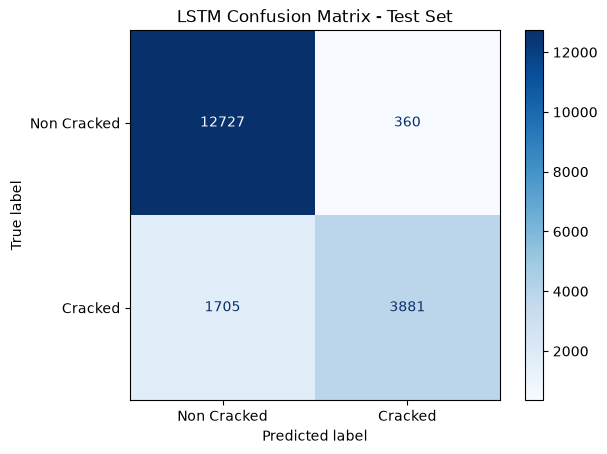

In [43]:

# Set model to evaluation mode
final_model.eval()

all_preds = []
all_labels = []

# Collect predictions and true labels
with torch.no_grad():
    for xb, yb in final_test_loader:
        xb = xb.to(device)

        outputs = final_model(xb)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(yb.cpu().numpy())

# Calculate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=[0, 1]
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non Cracked", "Cracked"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("LSTM Confusion Matrix - Test Set")
plt.show()

### Classification Report

In [45]:

report = classification_report(
    all_labels,
    all_preds,
    labels=[0, 1],
    target_names=["Non Cracked", "Cracked"],
    digits=4,
    zero_division=0
)

print("LSTM Classification Report - Test Set")
print("=" * 50)
print(report)

LSTM Classification Report - Test Set
              precision    recall  f1-score   support

 Non Cracked     0.8819    0.9725    0.9250     13087
     Cracked     0.9151    0.6948    0.7899      5586

    accuracy                         0.8894     18673
   macro avg     0.8985    0.8336    0.8574     18673
weighted avg     0.8918    0.8894    0.8845     18673



### Validation Probability Collection  

 Collect prediction probabilities on the validation set.
 We use these probabilities to test different classification thresholds
and improve the detection of Cracked images without retraining the model.

In [51]:

# Set model to evaluation mode
final_model.eval()

# Store predicted probabilities and actual labels
val_probs = []
val_labels = []

with torch.no_grad():
    for xb, yb in final_val_loader:

        xb = xb.to(device)

        # Get model predictions
        outputs = final_model(xb)

        # Calculate probabilities for the Cracked class (class 1)
        probs = torch.softmax(outputs, dim=1)[:, 1]

        val_probs.extend(probs.cpu().numpy())
        val_labels.extend(yb.cpu().numpy())

# Convert lists to NumPy arrays
val_probs = np.array(val_probs)
val_labels = np.array(val_labels)

print("Validation probabilities collected successfully!")
print("Total validation samples:", len(val_labels))

Validation probabilities collected successfully!
Total validation samples: 14054


### Classification Threshold Optimization

Evaluate different classification thresholds on the validation set.
 The goal is to find a better balance between Precision and Recall
for the Cracked class without retraining the LSTM model.

In [53]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Threshold values to evaluate
thresholds = [
    0.50, 0.48, 0.46, 0.44,
    0.42, 0.40, 0.38, 0.36
]
results = []

print(
    f"{'Threshold':<12}"
    f"{'Accuracy':<12}"
    f"{'Precision':<12}"
    f"{'Recall':<12}"
    f"{'F1-Score':<12}"
)

print("-" * 60)

for threshold in thresholds:

    # Classify images based on the selected threshold
    predictions = (val_probs >= threshold).astype(int)

    # Calculate evaluation metrics for Cracked class
    accuracy = accuracy_score(val_labels, predictions)

    precision = precision_score(
        val_labels, predictions, zero_division=0
    )

    recall = recall_score(
        val_labels, predictions, zero_division=0
    )

    f1 = f1_score(
        val_labels, predictions, zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print(
        f"{threshold:<12.2f}"
        f"{accuracy:<12.4f}"
        f"{precision:<12.4f}"
        f"{recall:<12.4f}"
        f"{f1:<12.4f}"
    )

Threshold   Accuracy    Precision   Recall      F1-Score    
------------------------------------------------------------
0.50        0.9010      0.9244      0.7289      0.8151      
0.48        0.9006      0.9210      0.7308      0.8149      
0.46        0.9002      0.9176      0.7327      0.8148      
0.44        0.8997      0.9144      0.7337      0.8141      
0.42        0.8991      0.9103      0.7356      0.8137      
0.40        0.8983      0.9060      0.7370      0.8128      
0.38        0.8967      0.8992      0.7377      0.8105      
0.36        0.8938      0.8854      0.7413      0.8069      


### Training Visualization

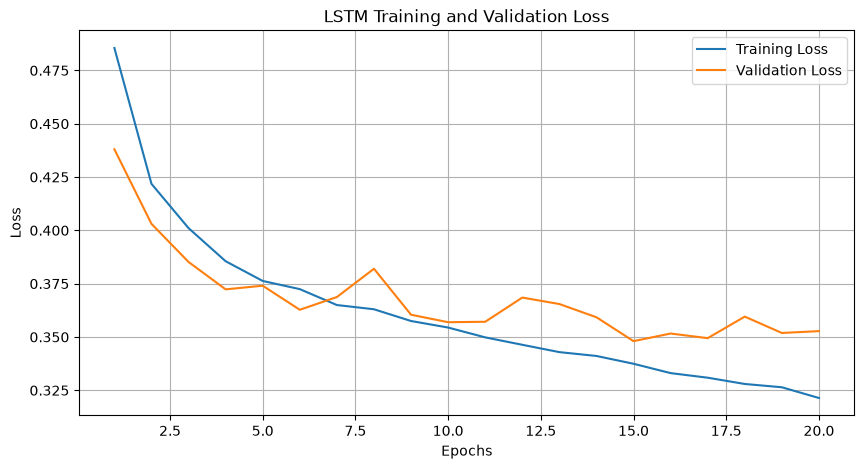

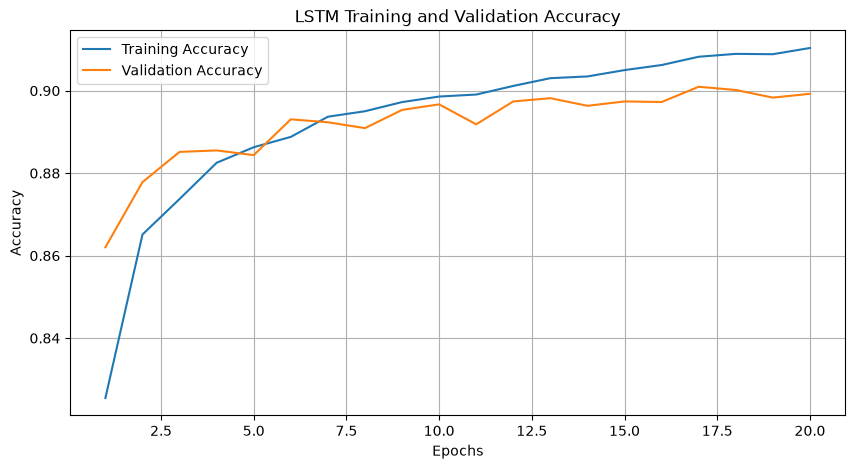

In [47]:

epochs_range = range(1, len(final_history["train_loss"]) + 1)

# 1. Loss Visualization
plt.figure(figsize=(10, 5))

plt.plot(epochs_range, final_history["train_loss"], label="Training Loss")
plt.plot(epochs_range, final_history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


# 2. Accuracy Visualization
plt.figure(figsize=(10, 5))

plt.plot(epochs_range, final_history["train_acc"], label="Training Accuracy")
plt.plot(epochs_range, final_history["val_acc"], label="Validation Accuracy")

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### Save Final Model

In [50]:


MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

final_model_path = MODELS_DIR / "final_lstm_model.pth"

# Load the best checkpoint
final_model.load_state_dict(
    torch.load(final_model_path, map_location=device)
)

# Save final model
torch.save({
    "model_state_dict": final_model.state_dict(),
    "best_params": best_params,
    "best_lr": best_lr,
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "test_macro_f1": 0.8574,
    "test_cracked_f1": 0.7899,
    "test_cracked_recall": 0.6948,
    "img_size": IMG_SIZE,
    "mean": mean,
    "std": std
}, MODELS_DIR / "lstm_final_checkpoint.pth")

print("Final LSTM model saved successfully!")
print("Path:", (MODELS_DIR / "lstm_final_checkpoint.pth").resolve())

Final LSTM model saved successfully!
Path: /run/media/nabil_darwish/New Volume/NINU/Level 3/sumester 1/Neural Network/project/GitHub/NN_Cracking_Classification/RNN(LSTM)/models/lstm_final_checkpoint.pth


# LSTM Improvement - Data Augmentation

### Check PyTorch Environment

In [61]:

print("Python Executable:", sys.executable)
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

try:
    import torchvision
    print("Torchvision Version:", torchvision.__version__)
except ImportError:
    print("Torchvision is not installed in this environment.")

Python Executable: /home/nabil_darwish/miniconda3/bin/python3.14
PyTorch Version: 2.15.0+cu132
CUDA Available: True
Torchvision Version: 0.29.2+cu132


###	Augmentation Configuration

In [62]:

AUGMENTATION_CONFIG = {
    "rotation_degrees": 10,
    "horizontal_flip": 0.5,
    "vertical_flip": 0.5,
    "brightness": 0.10,
    "contrast": 0.10
}

print("Data Augmentation Configuration:")
for name, value in AUGMENTATION_CONFIG.items():
    print(f"{name}: {value}")

Data Augmentation Configuration:
rotation_degrees: 10
horizontal_flip: 0.5
vertical_flip: 0.5
brightness: 0.1
contrast: 0.1


### 	Image Augmentation Function

In [63]:

augmentation_transform = transforms.Compose([
    transforms.RandomRotation(
        degrees=AUGMENTATION_CONFIG["rotation_degrees"]
    ),

    transforms.RandomHorizontalFlip(
        p=AUGMENTATION_CONFIG["horizontal_flip"]
    ),

    transforms.RandomVerticalFlip(
        p=AUGMENTATION_CONFIG["vertical_flip"]
    ),

    transforms.ColorJitter(
        brightness=AUGMENTATION_CONFIG["brightness"],
        contrast=AUGMENTATION_CONFIG["contrast"]
    )
])

print("Image Augmentation Function created successfully!")

Image Augmentation Function created successfully!


### Augmented CrackDataset

In [66]:


class AugmentedCrackDataset(Dataset):

    def __init__(self, X, y, transform=None):
        self.X = X
        self.y = y
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):

        # Convert NumPy image to PIL grayscale image
        image = Image.fromarray(self.X[i], mode="L")

        # Apply augmentation if provided
        if self.transform is not None:
            image = self.transform(image)

        # Convert image to NumPy array
        image = np.array(image, dtype=np.float32) / 255.0

        # Normalize image
        image = (image - mean) / std

        # Convert image to PyTorch tensor
        x = torch.from_numpy(image).float()

        # Get corresponding label
        label = torch.tensor(self.y[i], dtype=torch.long)

        return x, label


print("Augmented CrackDataset created successfully!")

Augmented CrackDataset created successfully!


### Augmented DataLoaders

In [67]:

def make_augmented_loader(X, y, batch_size, transform=None, shuffle=False):

    dataset = AugmentedCrackDataset(
        X=X,
        y=y,
        transform=transform
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        pin_memory=(device.type == "cuda")
    )


def get_augmented_loaders(batch_size):

    train_loader = make_augmented_loader(
        X_train,
        y_train,
        batch_size=batch_size,
        transform=augmentation_transform,
        shuffle=True
    )

    val_loader = make_augmented_loader(
        X_val,
        y_val,
        batch_size=batch_size,
        transform=None
    )

    test_loader = make_augmented_loader(
        X_test,
        y_test,
        batch_size=batch_size,
        transform=None
    )

    return train_loader, val_loader, test_loader


print("Augmented DataLoaders created successfully!")

Augmented DataLoaders created successfully!


### 	Improved LSTM Initialization

In [70]:
# Initialize the improved LSTM model
improved_model = LSTMClassifier(
    input_size=IMG_SIZE,
    hidden_size=best_params["hidden_size"],
    num_layers=best_params["num_layers"],
    dropout=best_params["dropout"]
)

# Move model to the selected device
improved_model = improved_model.to(device)

# Count trainable parameters
total_params = sum(
    p.numel() for p in improved_model.parameters()
    if p.requires_grad
)

print("Improved LSTM Model Initialized Successfully!")
print("-" * 45)

print(improved_model)
print("\nDevice:", device)
print("Hidden Size:", best_params["hidden_size"])
print("Number of Layers:", best_params["num_layers"])
print("Dropout:", best_params["dropout"])
print("Total Trainable Parameters:", total_params)

Improved LSTM Model Initialized Successfully!
---------------------------------------------
LSTMClassifier(
  (lstm): LSTM(128, 128, num_layers=3, batch_first=True)
  (fc): Linear(in_features=128, out_features=2, bias=True)
)

Device: cuda
Hidden Size: 128
Number of Layers: 3
Dropout: 0.0
Total Trainable Parameters: 396546


### Initialize Improved DataLoaders

In [72]:
improved_train_loader, improved_val_loader, improved_test_loader = (
    get_augmented_loaders(
        batch_size=best_params["batch_size"]
    )
)

print("Improved DataLoaders created successfully!")
print("Training batches:", len(improved_train_loader))
print("Validation batches:", len(improved_val_loader))
print("Test batches:", len(improved_test_loader))

Improved DataLoaders created successfully!
Training batches: 965
Validation batches: 220
Test batches: 292


### 	Improved Model Training

In [73]:
IMPROVED_MODEL_PATH = MODELS_DIR / "improved_lstm_model.pth"

improved_history = training(
    model=improved_model,
    train_loader=improved_train_loader,
    val_loader=improved_val_loader,
    epochs=20,
    optimizer_name=best_params["optimizer"],
    lr=best_lr,
    weight_decay=best_params["weight_decay"],
    scheduler_name=best_params["scheduler"],
    class_weights=class_weights.tolist(),
    save_path=IMPROVED_MODEL_PATH
)

print("\nImproved LSTM Training Completed!")


Epoch 1/20


  0%|          | 0/965 [00:00<?, ?it/s]

100%|██████████| 220/220 [00:02<00:00, 77.10it/s]


Train Loss: 0.5434
Train Accuracy: 0.7626
Validation Loss: 0.4507
Validation Accuracy: 0.8581
Best model saved!

Epoch 2/20


100%|██████████| 220/220 [00:02<00:00, 75.80it/s]


Train Loss: 0.4498
Train Accuracy: 0.8568
Validation Loss: 0.4422
Validation Accuracy: 0.8435

Epoch 3/20


... (32 outputs left out)

100%|██████████| 220/220 [00:02<00:00, 75.15it/s]


Train Loss: 0.3582
Train Accuracy: 0.8962
Validation Loss: 0.3533
Validation Accuracy: 0.8874

Epoch 20/20


100%|██████████| 220/220 [00:02<00:00, 77.57it/s]

Train Loss: 0.3566
Train Accuracy: 0.8978
Validation Loss: 0.3460
Validation Accuracy: 0.8943

Improved LSTM Training Completed!


### Improved Model Evaluation

In [74]:
# Load best improved model checkpoint
improved_model.load_state_dict(
    torch.load(IMPROVED_MODEL_PATH, map_location=device)
)

improved_model = improved_model.to(device)
improved_model.eval()

# Evaluate on validation set
evaluation_criterion = nn.CrossEntropyLoss()

improved_val_loss, improved_val_accuracy = run_epoch(
    improved_model,
    improved_val_loader,
    evaluation_criterion
)

print("Improved LSTM Validation Results")
print("-" * 40)
print(f"Validation Loss: {improved_val_loss:.4f}")
print(f"Validation Accuracy: {improved_val_accuracy * 100:.2f}%")

100%|██████████| 220/220 [00:03<00:00, 73.16it/s]

Improved LSTM Validation Results
----------------------------------------
Validation Loss: 0.3324
Validation Accuracy: 90.34%


### Improved Confusion Matrix & Classification Report

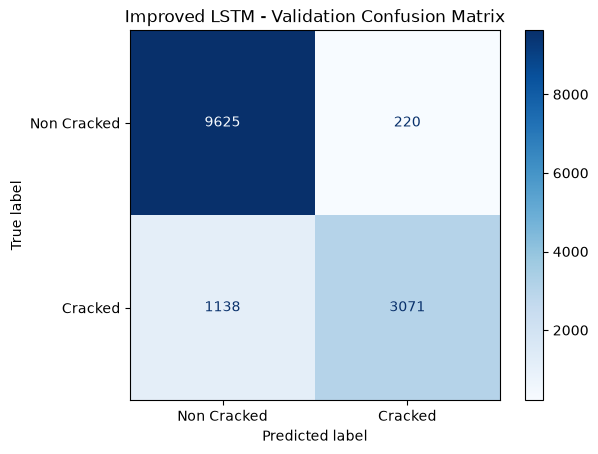


Improved LSTM Classification Report
              precision    recall  f1-score   support

 Non Cracked     0.8943    0.9777    0.9341      9845
     Cracked     0.9332    0.7296    0.8189      4209

    accuracy                         0.9034     14054
   macro avg     0.9137    0.8536    0.8765     14054
weighted avg     0.9059    0.9034    0.8996     14054



In [75]:

improved_model.eval()

improved_preds = []
improved_labels = []

with torch.no_grad():
    for xb, yb in improved_val_loader:

        xb = xb.to(device)

        outputs = improved_model(xb)
        predictions = outputs.argmax(dim=1)

        improved_preds.extend(predictions.cpu().numpy())
        improved_labels.extend(yb.cpu().numpy())

# Confusion Matrix
cm = confusion_matrix(
    improved_labels,
    improved_preds,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non Cracked", "Cracked"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Improved LSTM - Validation Confusion Matrix")
plt.show()

# Classification Report
print("\nImproved LSTM Classification Report")
print("=" * 55)

print(classification_report(
    improved_labels,
    improved_preds,
    labels=[0, 1],
    target_names=["Non Cracked", "Cracked"],
    digits=4,
    zero_division=0
))

### Performance Comparison

In [76]:
import pandas as pd

comparison_data = {
    "Metric": [
        "Accuracy",
        "Macro F1-Score",
        "Cracked Precision",
        "Cracked Recall",
        "Cracked F1-Score"
    ],

    "Baseline LSTM": [
        0.9010,
        0.8574,
        0.9244,
        0.7289,
        0.8151
    ],

    "Improved LSTM": [
        0.9034,
        0.8765,
        0.9332,
        0.7296,
        0.8189
    ]
}

comparison_df = pd.DataFrame(comparison_data)

comparison_df["Improvement"] = (
    comparison_df["Improved LSTM"] -
    comparison_df["Baseline LSTM"]
)

print("Baseline vs Improved LSTM Performance")
print("=" * 65)

display(
    comparison_df.style.format({
        "Baseline LSTM": "{:.4f}",
        "Improved LSTM": "{:.4f}",
        "Improvement": "{:+.4f}"
    })
)

Baseline vs Improved LSTM Performance


,Metric,Baseline LSTM,Improved LSTM,Improvement
0,Accuracy,0.9010,0.9034,+0.0024
1,Macro F1-Score,0.8574,0.8765,+0.0191
2,Cracked Precision,0.9244,0.9332,+0.0088
3,Cracked Recall,0.7289,0.7296,+0.0007
4,Cracked F1-Score,0.8151,0.8189,+0.0038


### Baseline Validation Evaluation

In [77]:

# Load the baseline model
final_model.load_state_dict(
    torch.load(
        MODELS_DIR / "final_lstm_model.pth",
        map_location=device
    )
)

final_model.eval()

baseline_val_preds = []
baseline_val_labels = []

with torch.no_grad():
    for xb, yb in final_val_loader:
        xb = xb.to(device)

        outputs = final_model(xb)
        predictions = outputs.argmax(dim=1)

        baseline_val_preds.extend(predictions.cpu().numpy())
        baseline_val_labels.extend(yb.cpu().numpy())

print("Baseline LSTM - Validation Report")
print("=" * 50)

print(classification_report(
    baseline_val_labels,
    baseline_val_preds,
    labels=[0, 1],
    target_names=["Non Cracked", "Cracked"],
    digits=4,
    zero_division=0
))

Baseline LSTM - Validation Report
              precision    recall  f1-score   support

 Non Cracked     0.8937    0.9745    0.9324      9845
     Cracked     0.9244    0.7289    0.8151      4209

    accuracy                         0.9010     14054
   macro avg     0.9090    0.8517    0.8737     14054
weighted avg     0.9029    0.9010    0.8972     14054



### Final Improved Test Evaluation
Comment:

In [79]:
from sklearn.metrics import classification_report, accuracy_score
# Load best improved checkpoint
improved_model.load_state_dict(
    torch.load(IMPROVED_MODEL_PATH, map_location=device)
)

improved_model.eval()

improved_test_preds = []
improved_test_labels = []

with torch.no_grad():
    for xb, yb in improved_test_loader:
        xb = xb.to(device)

        outputs = improved_model(xb)
        predictions = outputs.argmax(dim=1)

        improved_test_preds.extend(predictions.cpu().numpy())
        improved_test_labels.extend(yb.cpu().numpy())

# Calculate test accuracy
improved_test_accuracy = accuracy_score(
    improved_test_labels,
    improved_test_preds
)

print("Improved LSTM - Final Test Results")
print("=" * 55)

print(f"Test Accuracy: {improved_test_accuracy * 100:.2f}%")

print(classification_report(
    improved_test_labels,
    improved_test_preds,
    labels=[0, 1],
    target_names=["Non Cracked", "Cracked"],
    digits=4,
    zero_division=0
))

Improved LSTM - Final Test Results
Test Accuracy: 89.31%
              precision    recall  f1-score   support

 Non Cracked     0.8837    0.9759    0.9275     13087
     Cracked     0.9251    0.6991    0.7964      5586

    accuracy                         0.8931     18673
   macro avg     0.9044    0.8375    0.8619     18673
weighted avg     0.8961    0.8931    0.8883     18673

